# Pose Landmark Feature Analysis

Explore the extracted raw landmark features from training videos.
- Check data quality (missing values, class distribution)
- Visualize landmark distributions per exercise
- PCA separability check
- Classification test (RandomForest, matching notebook approach)

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette('tab20')

DATA_FILE = '../data/landmarks.csv'

df = pd.read_csv(DATA_FILE)
print(f'Raw data: {len(df)} samples, {df["label"].nunique()} classes')
print(f'Columns: {len(df.columns)} (label + 132 landmark features)')

feature_cols = [c for c in df.columns if c != 'label']
print(f'Feature columns: {len(feature_cols)}')
df.head()

Raw data: 36503 samples, 22 classes
Columns: 133 (label + 132 landmark features)
Feature columns: 132


,label,x0,y0,z0,v0,x1,y1,z1,v1,x2,...,z30,v30,x31,y31,z31,v31,x32,y32,z32,v32
0,barbell biceps curl,0.493668,0.334452,-0.457273,0.975483,0.509992,0.305607,-0.456974,0.955562,0.517254,...,0.335938,0.007481,0.513505,1.903120,0.248629,0.003646,0.438150,1.853648,0.153090,0.005067
1,barbell biceps curl,0.492685,0.333781,-0.435225,0.997500,0.508546,0.303583,-0.429406,0.994970,0.514820,...,0.441969,0.010520,0.555461,1.865792,0.168536,0.006647,0.488866,1.838448,0.272452,0.006816
2,barbell biceps curl,0.495120,0.341641,-0.487724,0.999052,0.511754,0.311620,-0.471236,0.997985,0.519279,...,0.341983,0.011407,0.533935,1.776583,0.034882,0.008458,0.467726,1.746433,0.167907,0.006723
3,barbell biceps curl,0.493776,0.337246,-0.358573,0.997164,0.509937,0.305626,-0.343627,0.994767,0.518128,...,0.271094,0.031666,0.536596,1.780033,0.062080,0.012479,0.464696,1.748973,0.111246,0.010017
4,barbell biceps curl,0.492922,0.335319,-0.319362,0.998826,0.509202,0.301855,-0.307513,0.998046,0.516109,...,0.221916,0.008029,0.536293,1.784066,-0.108482,0.003930,0.471416,1.761007,0.076074,0.002572


In [19]:
# Samples per class
class_counts = df['label'].value_counts().sort_values()
print(f'\nSamples per class:')
for label, count in class_counts.items():
    print(f'  {label:25s} {count:5d}')
print(f'\nTotal: {len(df)} samples across {df["label"].nunique()} classes')


Samples per class:
  shoulder press              949
  tricep dips                 962
  romanian deadlift          1172
  russian twist              1201
  hip thrust                 1259
  leg extension              1348
  decline bench press        1386
  pull up                    1454
  lateral raises             1515
  leg raises                 1515
  t bar row                  1542
  incline bench press        1636
  hammer curl                1641
  deadlift                   1775
  chest fly machine          1836
  tricep pushdown            1875
  lat pulldown               1881
  squat                      1900
  bench press                2149
  push up                    2170
  plank                      2629
  barbell biceps curl        2708

Total: 36503 samples across 22 classes


## 1. Class Distribution

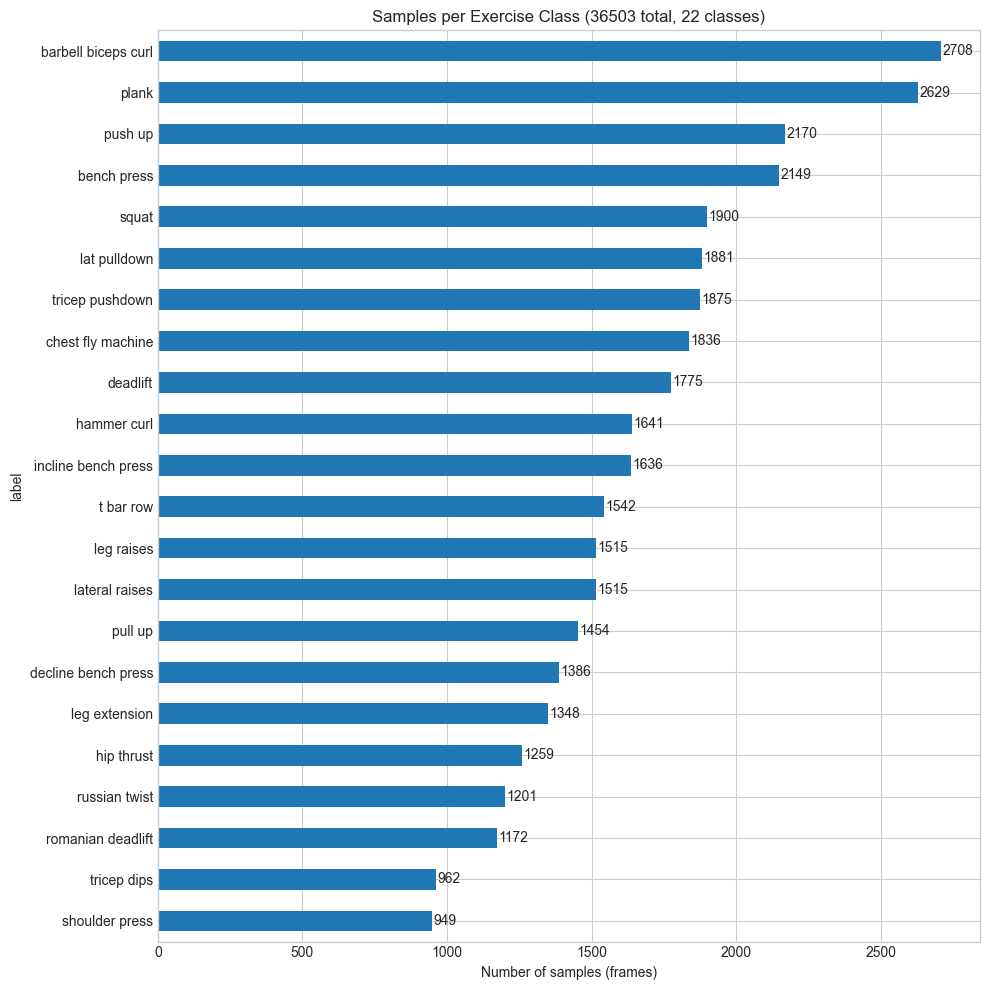

Min samples: 949 (shoulder press)
Max samples: 2708 (barbell biceps curl)
Mean: 1659, Std: 468
Imbalance ratio (max/min): 2.9x


In [20]:
fig, ax = plt.subplots(figsize=(10, 10))
class_counts.plot(kind='barh', ax=ax)
ax.set_xlabel('Number of samples (frames)')
ax.set_title(f'Samples per Exercise Class ({len(df)} total, {df["label"].nunique()} classes)')
for i, v in enumerate(class_counts):
    ax.text(v + 5, i, str(v), va='center')
plt.tight_layout()
plt.show()

print(f'Min samples: {class_counts.min()} ({class_counts.idxmin()})')
print(f'Max samples: {class_counts.max()} ({class_counts.idxmax()})')
print(f'Mean: {class_counts.mean():.0f}, Std: {class_counts.std():.0f}')
print(f'Imbalance ratio (max/min): {class_counts.max() / class_counts.min():.1f}x')

In [21]:
# Check for missing/null values
missing = df[feature_cols].isnull().sum()
if missing.sum() == 0:
    print('No missing values!')
else:
    print('Missing values:')
    print(missing[missing > 0])

# Check value ranges (landmarks should be normalized 0-1 for x,y)
print(f'\nFeature value ranges:')
print(f'  x columns: min={df[[c for c in feature_cols if c.startswith("x")]].min().min():.4f}, '
      f'max={df[[c for c in feature_cols if c.startswith("x")]].max().max():.4f}')
print(f'  y columns: min={df[[c for c in feature_cols if c.startswith("y")]].min().min():.4f}, '
      f'max={df[[c for c in feature_cols if c.startswith("y")]].max().max():.4f}')
print(f'  z columns: min={df[[c for c in feature_cols if c.startswith("z")]].min().min():.4f}, '
      f'max={df[[c for c in feature_cols if c.startswith("z")]].max().max():.4f}')
print(f'  v columns: min={df[[c for c in feature_cols if c.startswith("v")]].min().min():.4f}, '
      f'max={df[[c for c in feature_cols if c.startswith("v")]].max().max():.4f}')

No missing values!

Feature value ranges:
  x columns: min=-2.4579, max=3.0206
  y columns: min=-4.0423, max=5.2037
  z columns: min=-3.6541, max=5.6516
  v columns: min=0.0000, max=1.0000


## 2. Key Landmark Distributions

Compare key body landmarks (shoulders, hips, knees) across exercises.

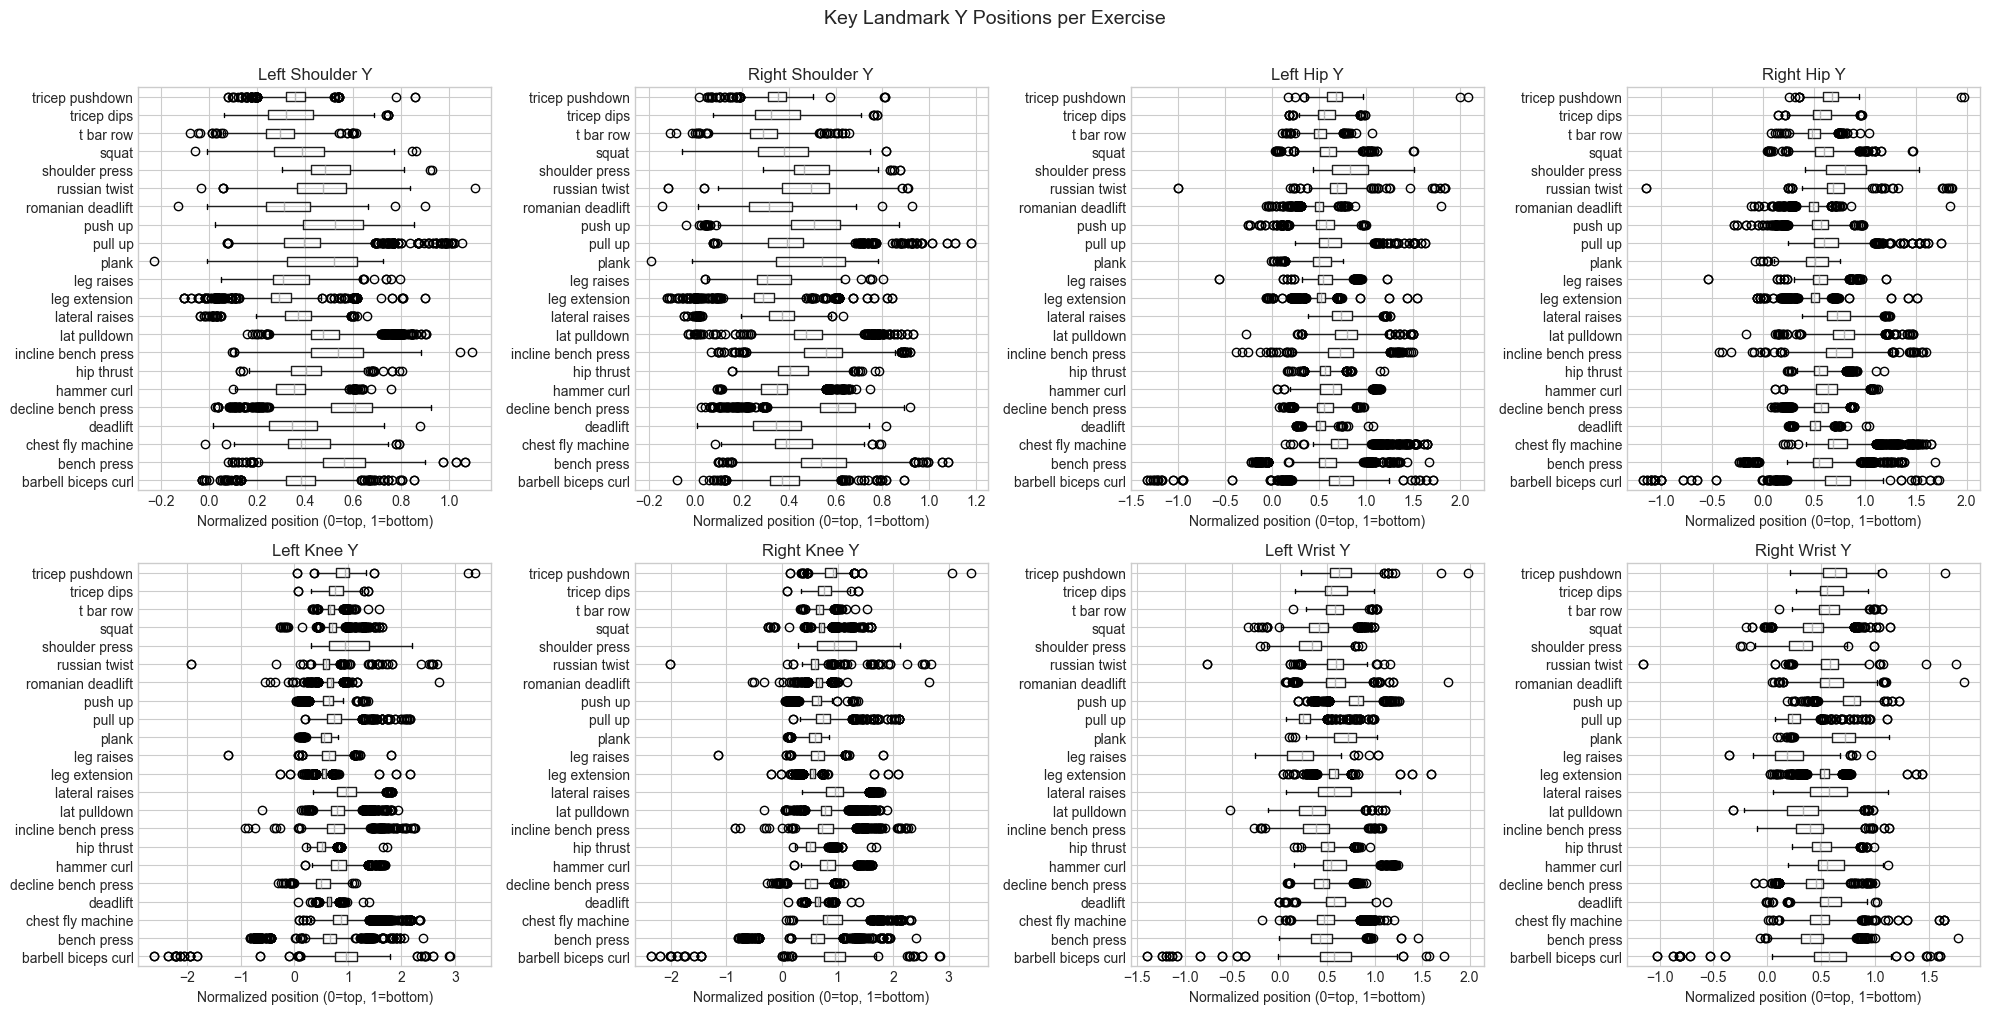

In [22]:
# Key landmark Y positions (vertical position is most discriminative)
# MediaPipe landmark indices: 11=L shoulder, 12=R shoulder, 23=L hip, 24=R hip, 25=L knee, 26=R knee
key_landmarks = {
    'Left Shoulder Y': 'y11', 'Right Shoulder Y': 'y12',
    'Left Hip Y': 'y23', 'Right Hip Y': 'y24',
    'Left Knee Y': 'y25', 'Right Knee Y': 'y26',
    'Left Wrist Y': 'y15', 'Right Wrist Y': 'y16',
}

fig, axes = plt.subplots(2, 4, figsize=(20, 10))
axes = axes.flatten()

for i, (name, col) in enumerate(key_landmarks.items()):
    ax = axes[i]
    order = df.groupby('label')[col].median().sort_values().index
    df.boxplot(column=col, by='label', ax=ax, vert=False)
    ax.set_title(name)
    ax.set_ylabel('')
    ax.set_xlabel('Normalized position (0=top, 1=bottom)')

plt.suptitle('Key Landmark Y Positions per Exercise', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

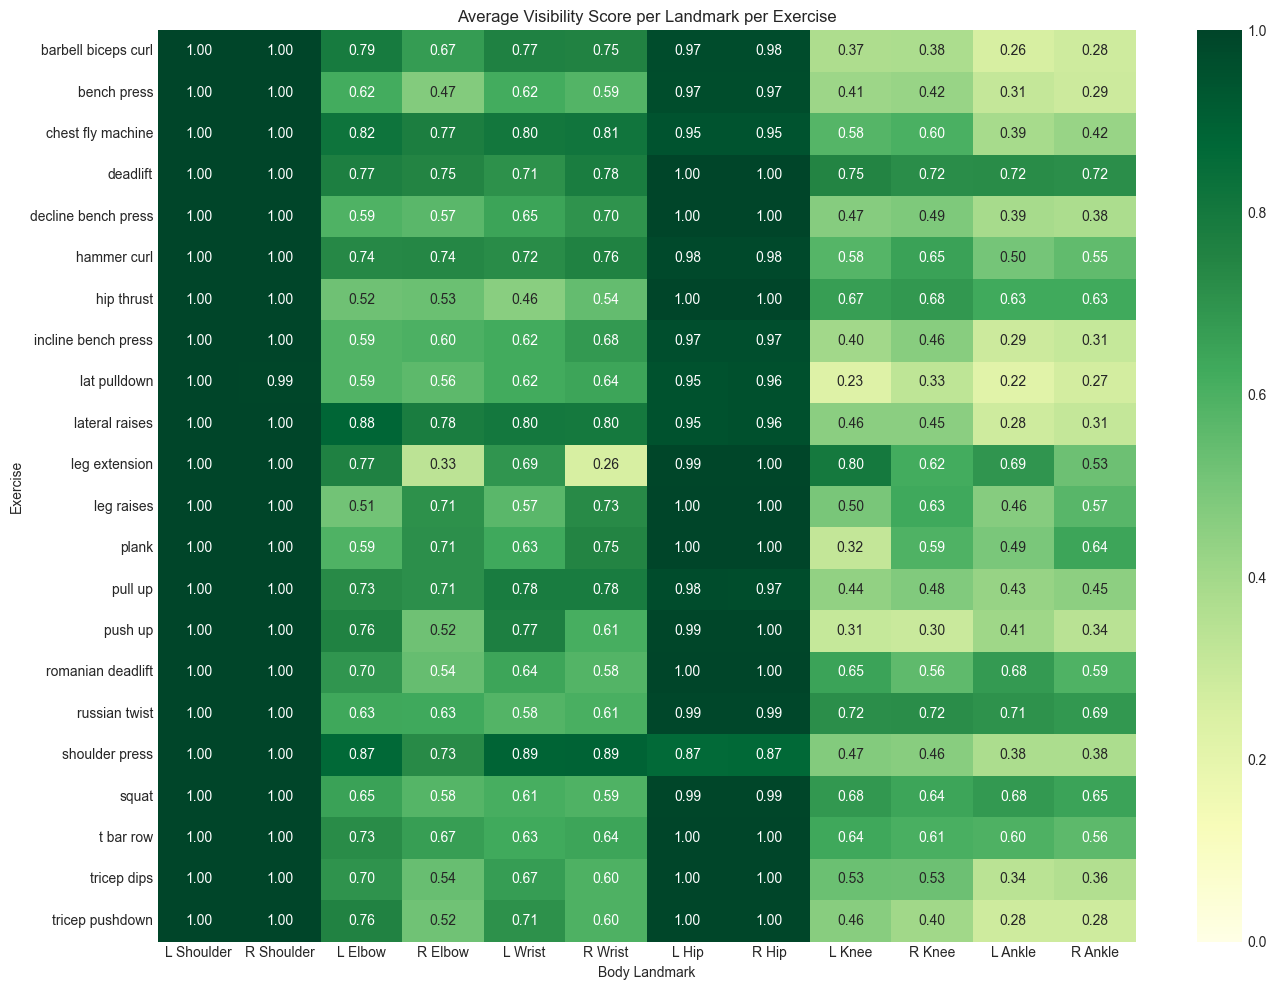

In [23]:
# Visibility scores for key landmarks
vis_cols = {f'v{i}': f'Landmark {i}' for i in [11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]}

vis_means = df.groupby('label')[[f'v{i}' for i in [11, 12, 13, 14, 15, 16, 23, 24, 25, 26, 27, 28]]].mean()
vis_means.columns = ['L Shoulder', 'R Shoulder', 'L Elbow', 'R Elbow', 'L Wrist', 'R Wrist',
                      'L Hip', 'R Hip', 'L Knee', 'R Knee', 'L Ankle', 'R Ankle']

fig, ax = plt.subplots(figsize=(14, 10))
sns.heatmap(vis_means, annot=True, fmt='.2f', cmap='YlGn', ax=ax, vmin=0, vmax=1)
ax.set_title('Average Visibility Score per Landmark per Exercise')
ax.set_xlabel('Body Landmark')
ax.set_ylabel('Exercise')
plt.tight_layout()
plt.show()

## 3. PCA Separability Check

Project all 132 features to 2D to see if classes form clusters.

/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: divide by zero encountered in matmul
  X_transformed = X @ self.components_.T
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: overflow encountered in matmul
  X_transformed = X @ self.components_.T
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_base.py:148: RuntimeWarning: inval

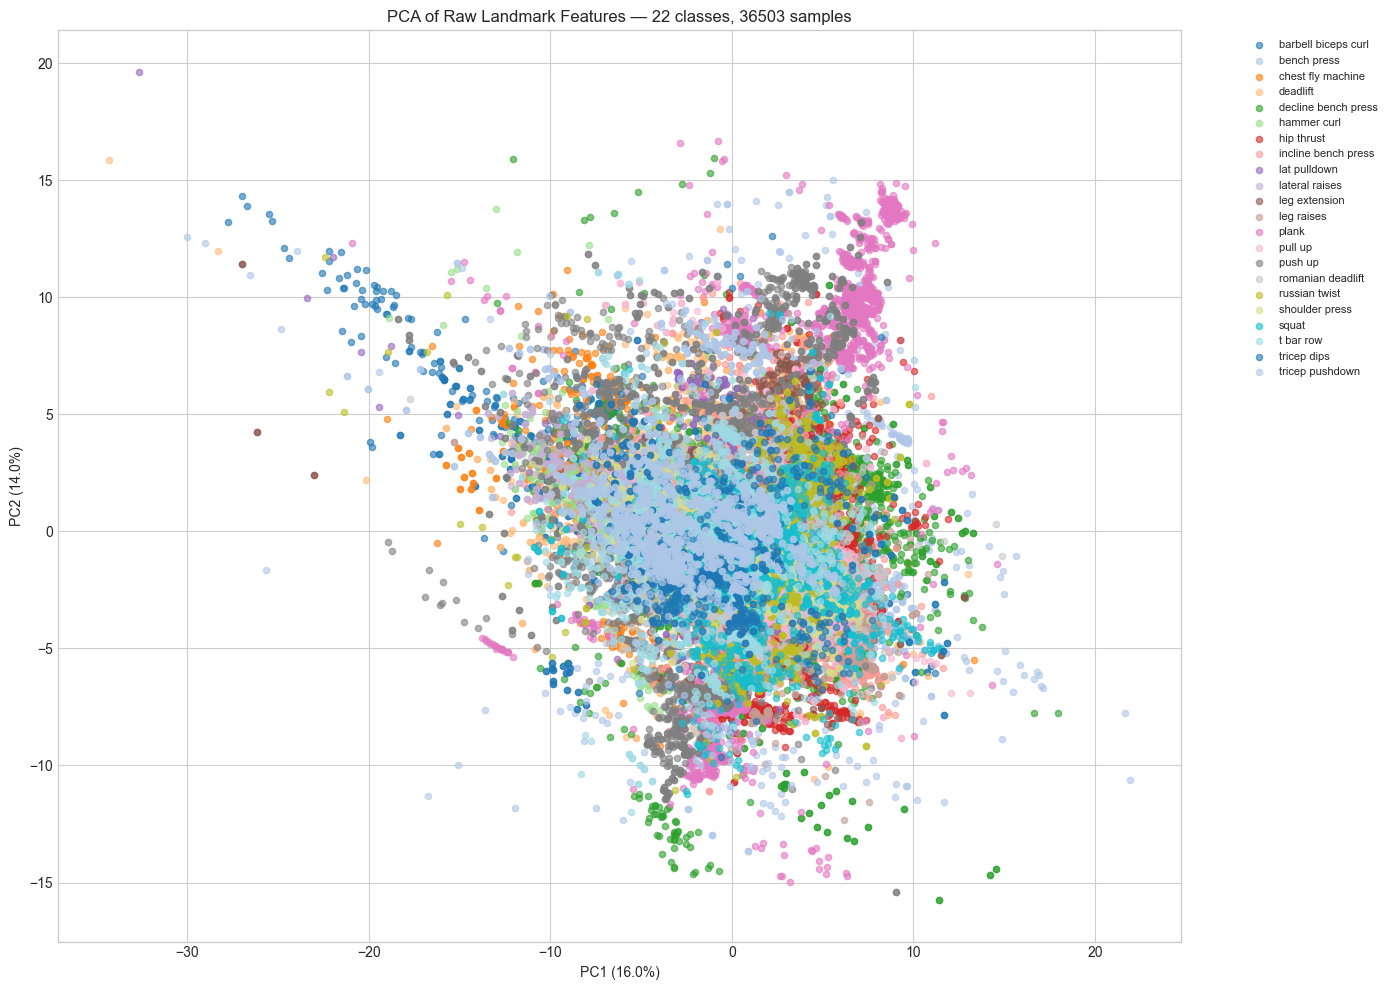

Variance explained by 2 components: 30.0%
Components for 90% variance: 12
Components for 95% variance: 17


/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: divide by zero encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: overflow encountered in matmul
  C = X.T @ X
/opt/miniconda3/envs/gym-monitoring/lib/python3.10/site-packages/sklearn/decomposition/_pca.py:604: RuntimeWarning: invalid value encountered in matmul
  C = X.T @ X


In [24]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X = df[feature_cols].values
X_scaled = StandardScaler().fit_transform(X)

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

fig, ax = plt.subplots(figsize=(14, 10))
labels = df['label'].values
unique_labels = sorted(df['label'].unique())

for label in unique_labels:
    mask = labels == label
    ax.scatter(X_pca[mask, 0], X_pca[mask, 1], label=label, alpha=0.6, s=20)

ax.set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
ax.set_title(f'PCA of Raw Landmark Features — {df["label"].nunique()} classes, {len(df)} samples')
ax.legend(bbox_to_anchor=(1.05, 1), loc='upper left', fontsize=8)
plt.tight_layout()
plt.show()

print(f'Variance explained by 2 components: {pca.explained_variance_ratio_.sum()*100:.1f}%')

pca_full = PCA().fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)
n90 = np.argmax(cumvar >= 0.90) + 1
n95 = np.argmax(cumvar >= 0.95) + 1
print(f'Components for 90% variance: {n90}')
print(f'Components for 95% variance: {n95}')

## 4. Classification Test (RandomForest)

Match the notebook approach: RandomForest with 300 trees, balanced class weights, max 2000 samples per class.

In [25]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, cross_val_predict, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix

# Balance classes (max 2000 samples per class, matching notebook)
max_samples_per_class = 2000
balanced_dfs = []
for label in df['label'].unique():
    label_df = df[df['label'] == label]
    if len(label_df) > max_samples_per_class:
        label_df = label_df.sample(n=max_samples_per_class, random_state=42)
    balanced_dfs.append(label_df)
df_balanced = pd.concat(balanced_dfs, ignore_index=True)
print(f'Balanced dataset: {len(df_balanced)} samples, {df_balanced["label"].nunique()} classes')

X = df_balanced[feature_cols].values
y = df_balanced['label'].values

# Train/test split (matching notebook: 80/20, stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f'Train: {len(X_train)}, Test: {len(X_test)}')

# Train RandomForest (matching notebook hyperparameters)
model = RandomForestClassifier(
    n_estimators=300,
    max_depth=25,
    min_samples_split=5,
    min_samples_leaf=2,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'\nTest accuracy: {(y_pred == y_test).mean():.1%}')
print(classification_report(y_test, y_pred, digits=2, zero_division=0))

Balanced dataset: 34847 samples, 22 classes
Train: 27877, Test: 6970

Test accuracy: 96.5%
                     precision    recall  f1-score   support

barbell biceps curl       0.93      0.94      0.94       400
        bench press       0.93      0.97      0.95       400
  chest fly machine       0.99      0.97      0.98       367
           deadlift       0.96      0.97      0.97       355
decline bench press       0.94      0.96      0.95       277
        hammer curl       0.98      0.94      0.96       328
         hip thrust       0.96      0.95      0.95       252
incline bench press       0.95      0.96      0.96       327
       lat pulldown       0.96      0.99      0.98       376
     lateral raises       0.99      0.96      0.97       303
      leg extension       0.99      0.99      0.99       270
         leg raises       0.97      0.99      0.98       303
              plank       0.99      0.98      0.99       400
            pull up       0.96      0.93      0.95    

## 5. Confusion Matrix

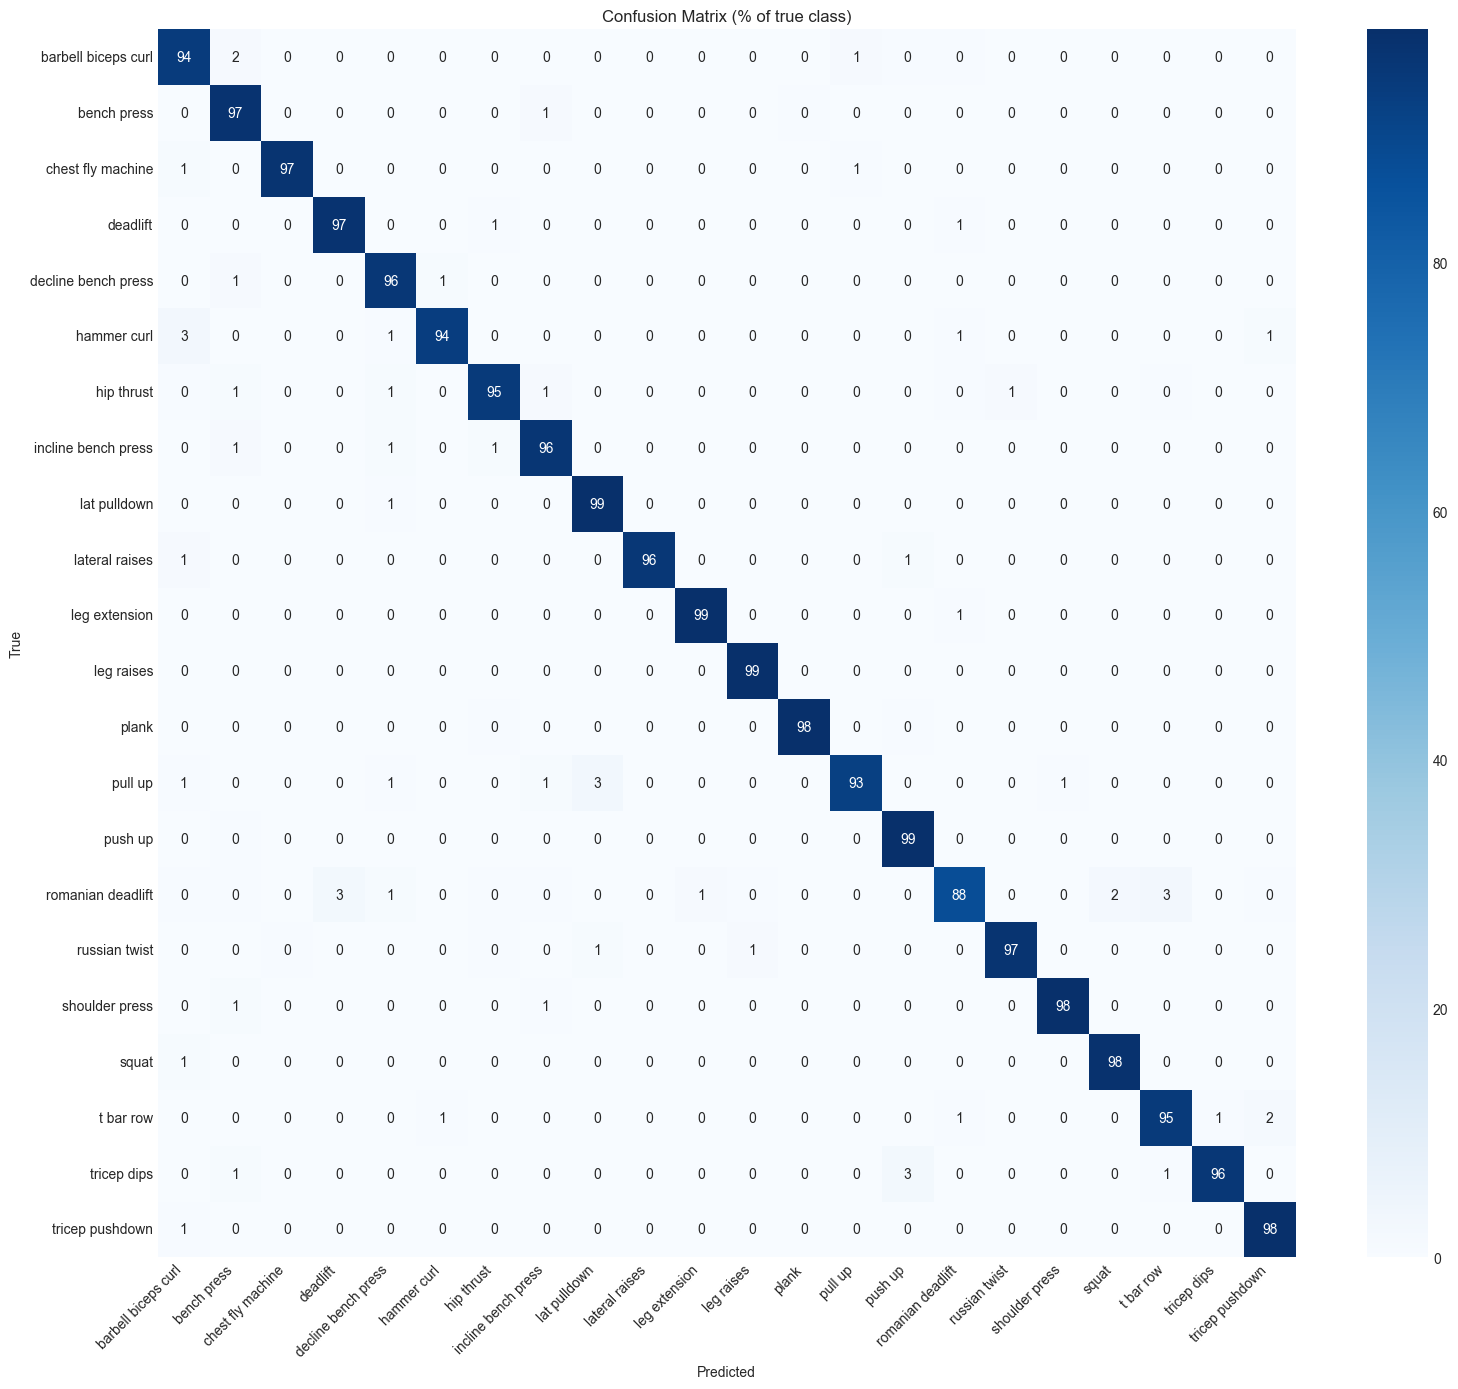

Most confused pairs:
  hammer curl -> barbell biceps curl: 10 times
  pull up -> lat pulldown: 9 times
  romanian deadlift -> t bar row: 7 times
  romanian deadlift -> deadlift: 6 times
  barbell biceps curl -> bench press: 6 times
  tricep dips -> push up: 5 times
  t bar row -> tricep pushdown: 5 times
  romanian deadlift -> squat: 5 times
  bench press -> incline bench press: 5 times
  barbell biceps curl -> pull up: 5 times
  squat -> barbell biceps curl: 4 times
  lateral raises -> barbell biceps curl: 4 times
  incline bench press -> bench press: 4 times
  decline bench press -> bench press: 4 times
  russian twist -> leg raises: 3 times


In [26]:
cm = confusion_matrix(y_test, y_pred, labels=sorted(df_balanced['label'].unique()))
cm_pct = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

class_names = sorted(df_balanced['label'].unique())

fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(cm_pct, annot=True, fmt='.0f', cmap='Blues', ax=ax,
            xticklabels=class_names, yticklabels=class_names)
ax.set_xlabel('Predicted')
ax.set_ylabel('True')
ax.set_title('Confusion Matrix (% of true class)')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# Most confused pairs
print('Most confused pairs:')
confusions = []
for i in range(len(class_names)):
    for j in range(len(class_names)):
        if i != j and cm[i, j] > 0:
            confusions.append((cm[i, j], class_names[i], class_names[j]))
confusions.sort(reverse=True)
for count, true_label, pred_label in confusions[:15]:
    print(f'  {true_label} -> {pred_label}: {count} times')

## 6. Feature Importance

Which landmarks matter most for classification?

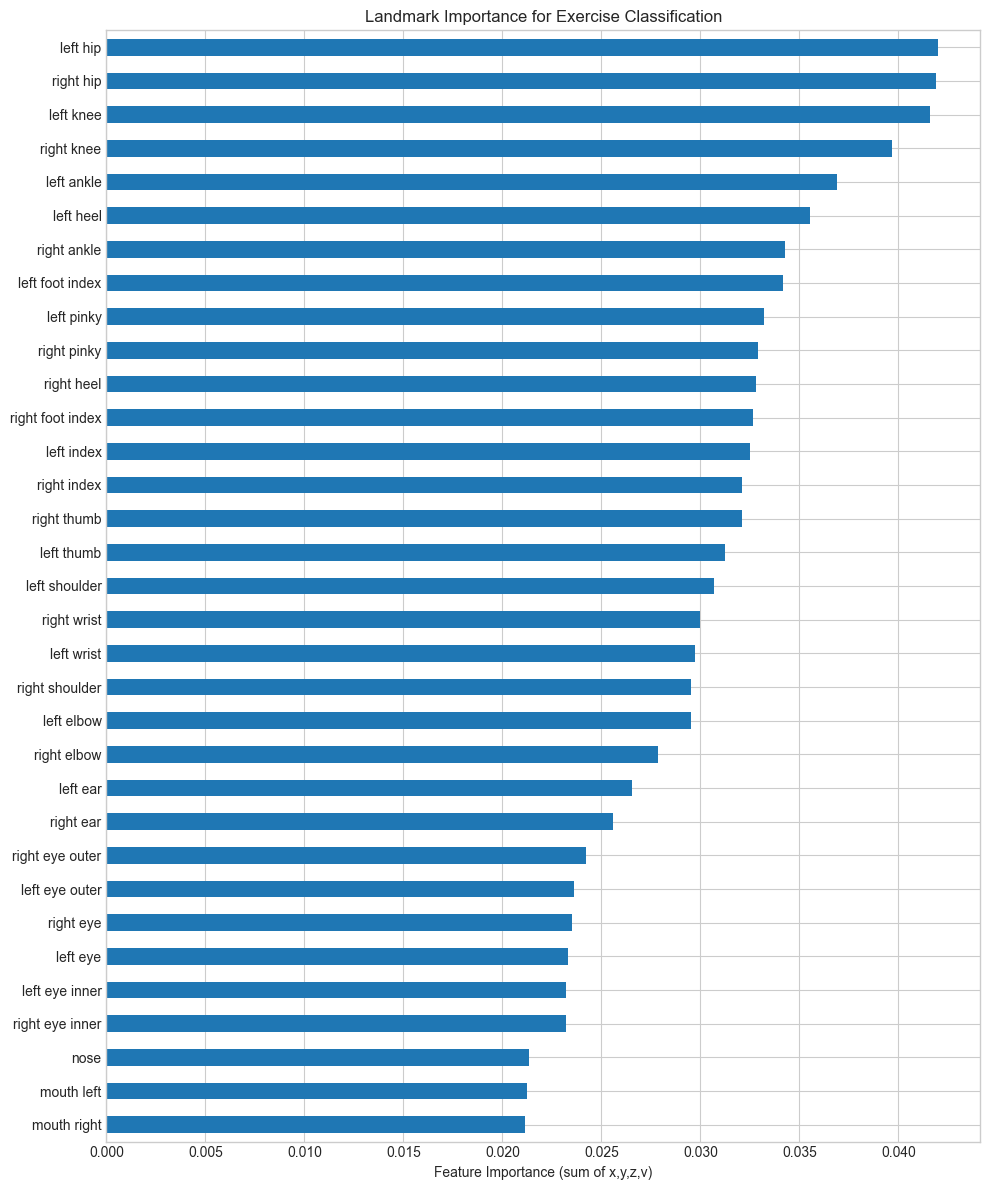

Top 10 most important landmarks:
  left hip: 0.0420
  right hip: 0.0419
  left knee: 0.0416
  right knee: 0.0397
  left ankle: 0.0369
  left heel: 0.0355
  right ankle: 0.0343
  left foot index: 0.0342
  left pinky: 0.0332
  right pinky: 0.0329


In [27]:
importances = pd.Series(model.feature_importances_, index=feature_cols)

# Group by landmark (sum x,y,z,v for each of 33 landmarks)
landmark_importance = {}
landmark_names = {
    0: 'nose', 1: 'left eye inner', 2: 'left eye', 3: 'left eye outer',
    4: 'right eye inner', 5: 'right eye', 6: 'right eye outer',
    7: 'left ear', 8: 'right ear', 9: 'mouth left', 10: 'mouth right',
    11: 'left shoulder', 12: 'right shoulder', 13: 'left elbow', 14: 'right elbow',
    15: 'left wrist', 16: 'right wrist', 17: 'left pinky', 18: 'right pinky',
    19: 'left index', 20: 'right index', 21: 'left thumb', 22: 'right thumb',
    23: 'left hip', 24: 'right hip', 25: 'left knee', 26: 'right knee',
    27: 'left ankle', 28: 'right ankle', 29: 'left heel', 30: 'right heel',
    31: 'left foot index', 32: 'right foot index',
}

for i in range(33):
    cols = [f'{c}{i}' for c in ['x', 'y', 'z', 'v']]
    name = landmark_names.get(i, f'landmark_{i}')
    landmark_importance[name] = importances[cols].sum()

lm_imp = pd.Series(landmark_importance).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 12))
lm_imp.plot(kind='barh', ax=ax)
ax.set_xlabel('Feature Importance (sum of x,y,z,v)')
ax.set_title('Landmark Importance for Exercise Classification')
plt.tight_layout()
plt.show()

print('Top 10 most important landmarks:')
for name, imp in lm_imp.tail(10).iloc[::-1].items():
    print(f'  {name}: {imp:.4f}')